# De Franceschi Mohamed
#### M2-IM

# HW2 : Convergence uniforme et limites de l'apprentissage

Ici on n'utilise pas de vraies données. On simule directement les lois de probabilité qui apparaissent dans les théorèmes du cours.

La partie I regarde comment l'erreur empirique $L_S(h)$ fluctue autour de l'erreur vraie $L_D(h)$, d'abord pour une hypothèse, puis pour toutes les hypothèses d'une classe $H$ en même temps. La partie II apprend des fonctions cibles tirées complètement au hasard, pour illustrer le No-Free-Lunch. La partie III remplace ces cibles par des seuils et montre qu'avec un biais inductif adapté, l'algorithme généralise.

Tout est codé avec NumPy, sans bibliothèque de machine learning.

## 0. Paramètres

| Paramètre | Valeur | Rôle |
|---|---|---|
| $p_j$ | entre 0,1 et 0,5 | erreurs vraies des hypothèses (0,5 est le cas où $L_S$ varie le plus) |
| $m$ (partie I) | de 10 à 1000 | tailles d'échantillon, assez variées pour voir la convergence |
| $\varepsilon$ | 0,1 | écart toléré entre $L_S$ et $L_D$ |
| $\delta$ | 0,05 | probabilité d'échec tolérée |
| $\lvert H \rvert$ | 5, 10, 50, 100, 500 | tailles de classe proposées dans l'énoncé |
| $N$ | 50, 100, 500 | tailles du domaine fini (parties II et III) |
| répétitions | 10 000 (partie I), 2000 (parties II et III) | nombre d'essais Monte-Carlo pour estimer une probabilité |

La partie I est rapide (on tire seulement des binomiales), on peut donc faire beaucoup de répétitions. Dans les parties II et III, chaque essai refait un apprentissage, alors on en fait moins.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)   # graine fixe pour des résultats reproductibles

EPS = 0.1
DELTA = 0.05
N_REPS = 10_000      # répétitions pour la partie I
N_REPS_2 = 2000      # répétitions pour les parties II et III

# Partie I : Simuler la convergence uniforme

Chaque hypothèse $h_j$ a une erreur vraie fixée $p_j$. Sur un échantillon de taille $m$, son nombre d'erreurs est $E_j \sim \text{Binomiale}(m, p_j)$ et son erreur empirique est $L_S(h_j) = E_j / m$.

## 1. L'erreur empirique est une variable aléatoire

On prend des hypothèses avec $p = 0{,}1$, $0{,}3$ et $0{,}5$. Pour chaque $m$, on tire $E_j$ 10 000 fois.

   p |    m | moyenne de L_S | écart-type de L_S | sqrt(p(1-p)/m)
 0.1 |   10 |         0.0990 |            0.0949 |         0.0949
 0.1 |   50 |         0.1004 |            0.0427 |         0.0424
 0.1 |  200 |         0.1001 |            0.0212 |         0.0212
 0.1 | 1000 |         0.0999 |            0.0095 |         0.0095
 0.3 |   10 |         0.3017 |            0.1443 |         0.1449
 0.3 |   50 |         0.3000 |            0.0644 |         0.0648
 0.3 |  200 |         0.2997 |            0.0324 |         0.0324
 0.3 | 1000 |         0.2999 |            0.0144 |         0.0145
 0.5 |   10 |         0.4983 |            0.1563 |         0.1581
 0.5 |   50 |         0.4996 |            0.0708 |         0.0707
 0.5 |  200 |         0.5001 |            0.0356 |         0.0354
 0.5 | 1000 |         0.5001 |            0.0156 |         0.0158


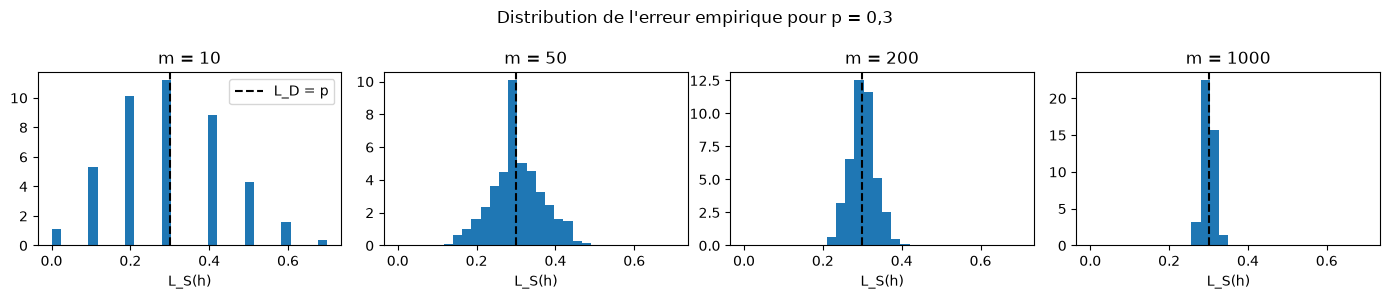

In [2]:
P_VALUES = [0.1, 0.3, 0.5]
M_HIST = [10, 50, 200, 1000]

def erreur_empirique(m, p, n_reps):
    # n_reps tirages de L_S = E / m avec E ~ Binomiale(m, p)
    E = rng.binomial(m, p, n_reps)
    return E / m

print("   p |    m | moyenne de L_S | écart-type de L_S | sqrt(p(1-p)/m)")
for p in P_VALUES:
    for m in M_HIST:
        L_S = erreur_empirique(m, p, N_REPS)
        print(f"{p:4.1f} | {m:4d} | {L_S.mean():14.4f} | {L_S.std():17.4f} | {np.sqrt(p * (1 - p) / m):14.4f}")

# histogrammes pour p = 0.3
p = 0.3
fig, axes = plt.subplots(1, len(M_HIST), figsize=(14, 3), sharex=True)
for ax, m in zip(axes, M_HIST):
    L_S = erreur_empirique(m, p, N_REPS)
    ax.hist(L_S, bins=30, range=(0, 0.7), density=True)
    ax.axvline(p, color="k", ls="--", label="L_D = p")
    ax.set_title(f"m = {m}")
    ax.set_xlabel("L_S(h)")
axes[0].legend()
fig.suptitle("Distribution de l'erreur empirique pour p = 0,3")
plt.tight_layout()
plt.show()

La moyenne de $L_S$ reste très proche de $p$. C'est attendu, puisque $\mathbb{E}[E_j/m] = p_j$ : l'erreur empirique est un estimateur sans biais de l'erreur vraie.

Quand $m$ augmente, la dispersion diminue. L'écart-type mesuré est presque égal à $\sqrt{p(1-p)/m}$, donc il est divisé par 2 quand $m$ est multiplié par 4. Sur les histogrammes la cloche se resserre autour de $p$. Avec $L_D = 0{,}3$ et $m = 10$, $L_S$ peut valoir 0 ou 0,6 ; avec $m = 1000$ il reste presque toujours entre 0,25 et 0,35. La dispersion est la plus grande pour $p = 0{,}5$.

## 2. Écart entre erreur empirique et erreur vraie

On fixe $\varepsilon = 0{,}1$ et une hypothèse avec $p = 0{,}5$ (le pire cas pour la variance). Pour chaque $m$ on estime $\Pr[|L_S(h) - L_D(h)| > \varepsilon]$ et on la compare à la borne de Hoeffding $2e^{-2m\varepsilon^2}$.

    m | Pr expérimentale | borne de Hoeffding
   10 |           0.3415 |             1.6375
   20 |           0.2569 |             1.3406
   50 |           0.1151 |             0.7358
  100 |           0.0311 |             0.2707
  150 |           0.0109 |             0.0996
  200 |           0.0039 |             0.0366
  300 |           0.0007 |             0.0050
  500 |           0.0000 |             0.0001
 1000 |           0.0000 |             0.0000


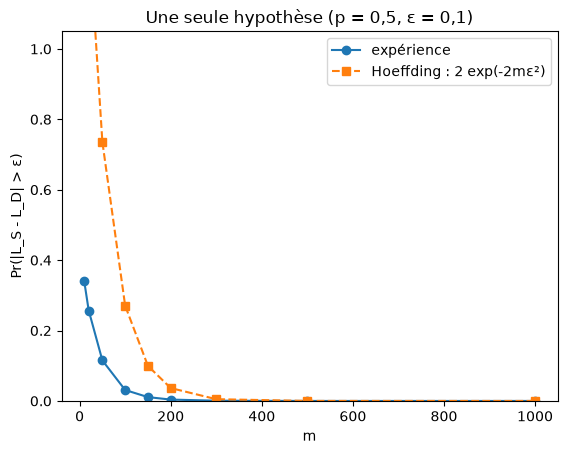

In [3]:
M_VALUES = [10, 20, 50, 100, 150, 200, 300, 500, 1000]
p = 0.5

def proba_ecart(m, p, eps):
    L_S = erreur_empirique(m, p, N_REPS)
    return np.mean(np.abs(L_S - p) > eps)

proba_exp = [proba_ecart(m, p, EPS) for m in M_VALUES]
hoeffding = [2 * np.exp(-2 * m * EPS**2) for m in M_VALUES]

print("    m | Pr expérimentale | borne de Hoeffding")
for m, pe, b in zip(M_VALUES, proba_exp, hoeffding):
    print(f"{m:5d} | {pe:16.4f} | {b:18.4f}")

plt.plot(M_VALUES, proba_exp, "o-", label="expérience")
plt.plot(M_VALUES, hoeffding, "s--", label="Hoeffding : 2 exp(-2mε²)")
plt.ylim(0, 1.05)
plt.xlabel("m"); plt.ylabel("Pr(|L_S - L_D| > ε)"); plt.legend()
plt.title("Une seule hypothèse (p = 0,5, ε = 0,1)")
plt.show()

La courbe expérimentale reste toujours sous la borne, donc Hoeffding est respecté. La borne est par contre assez large. Pour $m \le 20$ elle dépasse 1 et n'apporte aucune information. Pour les grands $m$ elle vaut environ 10 fois la vraie probabilité : à $m = 200$, la borne donne 0,037 et l'expérience 0,004.

Hoeffding s'applique à n'importe quelle moyenne de variables indépendantes à valeurs dans $[0, 1]$. Elle n'utilise pas le fait que nos erreurs suivent une binomiale et doit rester vraie dans le pire cas, ce qui la rend conservatrice.

## 3. D'une hypothèse à la convergence uniforme

On prend maintenant une classe de $K = 10$ hypothèses avec des erreurs vraies réparties entre 0,1 et 0,5. Pour chaque échantillon simulé on calcule les 10 erreurs empiriques et le plus grand écart
$$\Delta_S = \max_{h \in H} |L_S(h) - L_D(h)|.$$

Dans cette simulation simplifiée, les $E_j$ sont tirés indépendamment pour chaque hypothèse.

p_j = [0.1   0.144 0.189 0.233 0.278 0.322 0.367 0.411 0.456 0.5  ]



    m | Pr(Δ_S > ε) | une hypothèse (p=0.5) | borne 2|H|exp(-2mε²)
   10 |      0.9964 |                0.3415 |              16.3746
   20 |      0.9620 |                0.2569 |              13.4064
   50 |      0.6603 |                0.1151 |               7.3576
  100 |      0.2237 |                0.0311 |               2.7067
  150 |      0.0648 |                0.0109 |               0.9957
  200 |      0.0215 |                0.0039 |               0.3663
  300 |      0.0023 |                0.0007 |               0.0496
  500 |      0.0000 |                0.0000 |               0.0009
 1000 |      0.0000 |                0.0000 |               0.0000


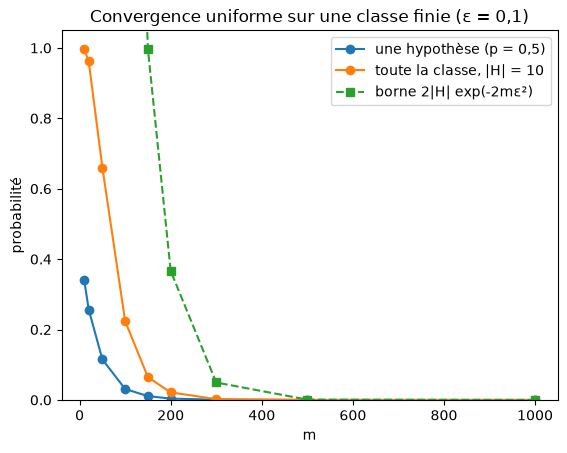

In [4]:
def proba_delta(m, p_vec, eps, n_reps):
    # proportion des échantillons où le pire écart sur H dépasse eps
    E = rng.binomial(m, p_vec, size=(n_reps, len(p_vec)))   # une ligne = un échantillon
    L_S = E / m
    delta_S = np.max(np.abs(L_S - p_vec), axis=1)            # max sur les hypothèses
    return np.mean(delta_S > eps)

K = 10
p_vec = np.linspace(0.1, 0.5, K)
print("p_j =", np.round(p_vec, 3))

proba_unif = [proba_delta(m, p_vec, EPS, N_REPS) for m in M_VALUES]
borne_unif = [2 * K * np.exp(-2 * m * EPS**2) for m in M_VALUES]

print()
print("    m | Pr(Δ_S > ε) | une hypothèse (p=0.5) | borne 2|H|exp(-2mε²)")
for m, pu, pe, b in zip(M_VALUES, proba_unif, proba_exp, borne_unif):
    print(f"{m:5d} | {pu:11.4f} | {pe:21.4f} | {b:20.4f}")

plt.plot(M_VALUES, proba_exp, "o-", label="une hypothèse (p = 0,5)")
plt.plot(M_VALUES, proba_unif, "o-", label=f"toute la classe, |H| = {K}")
plt.plot(M_VALUES, borne_unif, "s--", label="borne 2|H| exp(-2mε²)")
plt.ylim(0, 1.05)
plt.xlabel("m"); plt.ylabel("probabilité"); plt.legend()
plt.title("Convergence uniforme sur une classe finie (ε = 0,1)")
plt.show()

$\Pr[\Delta_S > \varepsilon]$ est plus grande que pour une seule hypothèse. Il suffit qu'une des 10 hypothèses tombe sur un mauvais échantillon pour que $\Delta_S$ dépasse $\varepsilon$, et plus il y a d'hypothèses, plus ça arrive souvent.

La borne $2|H|e^{-2m\varepsilon^2}$ vient de la borne de l'union : on additionne les probabilités d'échec des 10 hypothèses. Elle reste au-dessus de l'expérience, avec encore plus de marge que pour une hypothèse seule. Elle doit en effet couvrir le cas où toutes les hypothèses ont $p = 0{,}5$ et où leurs échecs n'arrivent jamais en même temps. $\Pr[\Delta_S > \varepsilon]$ tend quand même vers 0 quand $m$ augmente : on a bien la convergence uniforme sur cette classe.

## 4. Effet de la taille de la classe

On garde $\varepsilon = 0{,}1$ et on refait l'expérience pour $|H| = 5, 10, 50, 100, 500$. À chaque fois les $p_j$ sont répartis entre 0,1 et 0,5.

    m | |H|=  5 | |H|= 10 | |H|= 50 | |H|=100 | |H|=500
   10 |  0.9035 |  0.9965 |  1.0000 |  1.0000 |  1.0000
   20 |  0.7603 |  0.9667 |  1.0000 |  1.0000 |  1.0000
   50 |  0.3718 |  0.6649 |  0.9968 |  1.0000 |  1.0000
  100 |  0.1090 |  0.2277 |  0.7328 |  0.9350 |  1.0000
  150 |  0.0323 |  0.0682 |  0.3068 |  0.5210 |  0.9744
  200 |  0.0101 |  0.0217 |  0.1013 |  0.1955 |  0.6510
  300 |  0.0005 |  0.0015 |  0.0106 |  0.0222 |  0.0988
  500 |  0.0000 |  0.0000 |  0.0001 |  0.0002 |  0.0014
 1000 |  0.0000 |  0.0000 |  0.0000 |  0.0000 |  0.0000


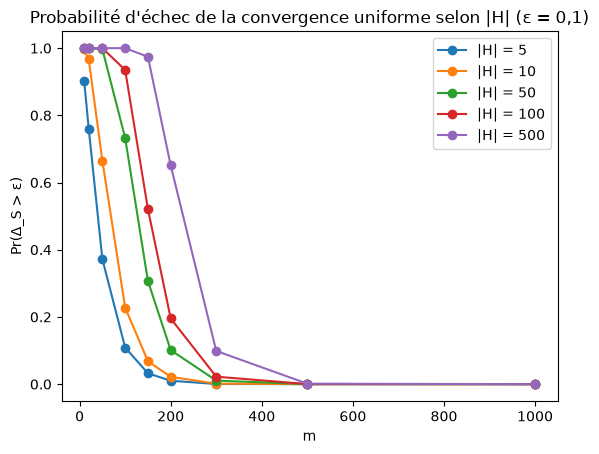

In [5]:
K_VALUES = [5, 10, 50, 100, 500]

resultats = {}
for K in K_VALUES:
    p_vec = np.linspace(0.1, 0.5, K)
    resultats[K] = [proba_delta(m, p_vec, EPS, N_REPS) for m in M_VALUES]

print("    m | " + " | ".join(f"|H|={K:3d}" for K in K_VALUES))
for i, m in enumerate(M_VALUES):
    print(f"{m:5d} | " + " | ".join(f"{resultats[K][i]:7.4f}" for K in K_VALUES))

for K in K_VALUES:
    plt.plot(M_VALUES, resultats[K], "o-", label=f"|H| = {K}")
plt.xlabel("m"); plt.ylabel("Pr(Δ_S > ε)"); plt.legend()
plt.title("Probabilité d'échec de la convergence uniforme selon |H| (ε = 0,1)")
plt.show()

Plus la classe est grande, plus la courbe est haute. Avec plus d'hypothèses, il y a plus de chances qu'au moins une s'écarte de sa vraie erreur.

Une grande classe demande donc plus de données pour la même probabilité d'échec. L'effet reste modéré : avec 100 fois plus d'hypothèses (500 au lieu de 5), il faut environ 200 exemples de plus (voir aussi la partie 5).

La borne prévoit ce comportement. $2|H|e^{-2m\varepsilon^2} \le \delta$ donne $m \ge \log(2|H|/\delta)/(2\varepsilon^2)$, donc multiplier $|H|$ par 100 ajoute $\log(100)/(2\varepsilon^2) \approx 230$ exemples. La taille de la classe intervient par son logarithme, et c'est pour ça que les courbes restent assez proches les unes des autres.

## 5. Complexité d'échantillon expérimentale

On fixe $\varepsilon = 0{,}1$ et $\delta = 0{,}05$. Pour chaque $|H|$ on teste $m = 10, 20, 30, \dots, 700$ et on garde le plus petit $m$ tel que $\Pr[\Delta_S > \varepsilon] \le \delta$. On le compare à la taille suffisante donnée par la théorie :
$$m \ge \frac{\log(2|H|/\delta)}{2\varepsilon^2}.$$

On fait 2000 répétitions par valeur de $m$, sinon le calcul est long.

|H| | m expérimental | m théorique | rapport théorie / expérience
  5 |            140 |         265 |   1.89
 10 |            170 |         300 |   1.76
 50 |            230 |         381 |   1.66
100 |            260 |         415 |   1.60
500 |            340 |         496 |   1.46


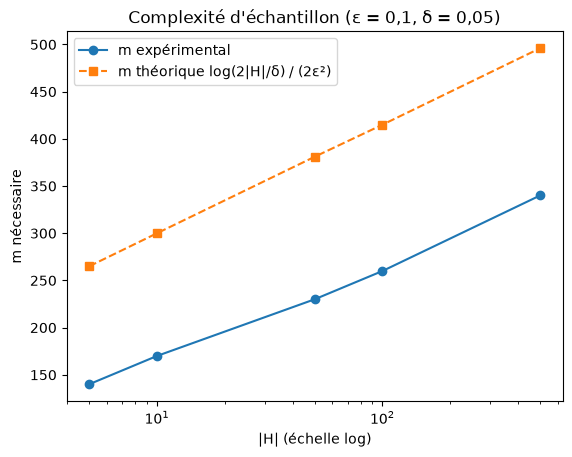

In [6]:
M_GRILLE = range(10, 701, 10)

def m_experimental(p_vec, eps, delta):
    # plus petit m testé tel que Pr(Δ_S > eps) <= delta
    for m in M_GRILLE:
        if proba_delta(m, p_vec, eps, N_REPS_2) <= delta:
            return m
    return None

m_exp = []
m_theo = []
for K in K_VALUES:
    p_vec = np.linspace(0.1, 0.5, K)
    m_exp.append(m_experimental(p_vec, EPS, DELTA))
    m_theo.append(int(np.ceil(np.log(2 * K / DELTA) / (2 * EPS**2))))

print("|H| | m expérimental | m théorique | rapport théorie / expérience")
for K, me, mt in zip(K_VALUES, m_exp, m_theo):
    print(f"{K:3d} | {me:14d} | {mt:11d} | {mt / me:6.2f}")

plt.plot(K_VALUES, m_exp, "o-", label="m expérimental")
plt.plot(K_VALUES, m_theo, "s--", label="m théorique log(2|H|/δ) / (2ε²)")
plt.xscale("log")
plt.xlabel("|H| (échelle log)"); plt.ylabel("m nécessaire"); plt.legend()
plt.title("Complexité d'échantillon (ε = 0,1, δ = 0,05)")
plt.show()

Pour chaque $|H|$, le $m$ théorique est 1,5 à 1,9 fois plus grand que le $m$ expérimental. Avec $|H|$ en échelle log, les deux courbes sont presque des droites. Elles croissent donc toutes les deux comme $\log|H|$, et la théorie a la bonne forme.

La borne est une condition suffisante. Si $m$ la dépasse, $\Pr[\Delta_S > \varepsilon] \le \delta$ est garanti quelles que soient les erreurs $p_j$ et la dépendance entre les hypothèses. Pour avoir une garantie aussi générale, on passe par Hoeffding, qui couvre le pire cas sur la loi des erreurs, et par la borne de l'union, qui couvre le cas où les échecs ne se chevauchent jamais. Notre problème n'atteint pas ces pires cas, donc il lui faut moins d'exemples. La borne ne donne pas le $m$ minimal exact.

# Partie II : Simuler le No-Free-Lunch

Le domaine est maintenant fini, $\mathcal{X} = \{1, \dots, N\}$, avec la loi uniforme. À chaque essai on tire une nouvelle cible $f$ : chaque $f(x)$ est un pile ou face indépendant. Le label d'un point ne dit donc rien sur celui d'un autre point.

L'algorithme apprend par cœur. Si $x$ est dans l'échantillon, il prédit le label observé, sinon il prédit 0.

Dans le code, les points sont numérotés de 0 à $N-1$ pour servir d'indices de tableau.

In [7]:
def tirer_cible_aleatoire(N):
    # f(x) ~ Bernoulli(1/2) pour chaque x, indépendamment
    return rng.integers(0, 2, N)

def tirer_echantillon(N, m):
    # m points tirés uniformément dans le domaine (avec remise)
    return rng.integers(0, N, m)

def apprendre_par_coeur(x_S, f, N, regle="0"):
    # renvoie les prédictions sur tout le domaine
    pred = np.full(N, -1)        # -1 = point jamais vu
    pred[x_S] = f[x_S]           # on recopie les labels vus
    non_vus = pred == -1
    if regle == "0":
        pred[non_vus] = 0
    elif regle == "1":
        pred[non_vus] = 1
    else:                        # "hasard" : pile ou face
        pred[non_vus] = rng.integers(0, 2, non_vus.sum())
    return pred

## 6. Points vus et non vus

Pour plusieurs $N$ et $m$, on mesure la fraction de points du domaine qui n'apparaissent pas dans l'échantillon, et on la compare à $(1 - 1/N)^m$.

   N |    m | fraction non vue (exp.) | (1 - 1/N)^m
  50 |    0 |                  1.0000 |      1.0000
  50 |   10 |                  0.8166 |      0.8171
  50 |   25 |                  0.6043 |      0.6035
  50 |   50 |                  0.3649 |      0.3642
  50 |  100 |                  0.1335 |      0.1326
  50 |  200 |                  0.0173 |      0.0176
  50 |  300 |                  0.0024 |      0.0023
  50 |  500 |                  0.0000 |      0.0000
  50 | 1000 |                  0.0000 |      0.0000


 100 |    0 |                  1.0000 |      1.0000
 100 |   10 |                  0.9045 |      0.9044
 100 |   25 |                  0.7777 |      0.7778
 100 |   50 |                  0.6050 |      0.6050
 100 |  100 |                  0.3662 |      0.3660
 100 |  200 |                  0.1343 |      0.1340
 100 |  300 |                  0.0494 |      0.0490
 100 |  500 |                  0.0065 |      0.0066
 100 | 1000 |                  0.0001 |      0.0000


 500 |    0 |                  1.0000 |      1.0000
 500 |   10 |                  0.9802 |      0.9802
 500 |   25 |                  0.9512 |      0.9512
 500 |   50 |                  0.9049 |      0.9047
 500 |  100 |                  0.8185 |      0.8186
 500 |  200 |                  0.6698 |      0.6701
 500 |  300 |                  0.5488 |      0.5485
 500 |  500 |                  0.3674 |      0.3675
 500 | 1000 |                  0.1349 |      0.1351


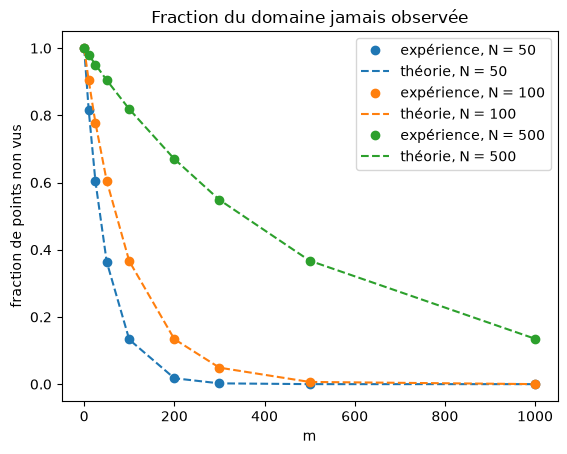

In [8]:
N_VALUES = [50, 100, 500]
M_VALUES_2 = [0, 10, 25, 50, 100, 200, 300, 500, 1000]

def fraction_non_vus(N, m):
    fractions = []
    for _ in range(N_REPS_2):
        x_S = tirer_echantillon(N, m)
        vus = np.zeros(N, dtype=bool)
        vus[x_S] = True
        fractions.append(1 - vus.mean())
    return np.mean(fractions)

print("   N |    m | fraction non vue (exp.) | (1 - 1/N)^m")
for N in N_VALUES:
    exp = [fraction_non_vus(N, m) for m in M_VALUES_2]
    theo = [(1 - 1 / N) ** m for m in M_VALUES_2]
    for m, e, t in zip(M_VALUES_2, exp, theo):
        print(f"{N:4d} | {m:4d} | {e:23.4f} | {t:11.4f}")
    plt.plot(M_VALUES_2, exp, "o", label=f"expérience, N = {N}")
    plt.plot(M_VALUES_2, theo, "--", color=plt.gca().lines[-1].get_color(), label=f"théorie, N = {N}")
plt.xlabel("m"); plt.ylabel("fraction de points non vus"); plt.legend()
plt.title("Fraction du domaine jamais observée")
plt.show()

Les points expérimentaux tombent sur les courbes théoriques.

Pour un point $x$ fixé, chaque tirage tombe sur un autre point avec probabilité $1 - 1/N$. Les $m$ tirages sont indépendants, donc $\Pr[x \text{ non vu}] = (1-1/N)^m$.

La fraction de points non vus vaut $\frac{1}{N}\sum_x \mathbb{1}[x \text{ non vu}]$. Par linéarité de l'espérance, et comme tous les points ont la même probabilité d'être non vus, $\mathbb{E}[\text{fraction}] = \frac{1}{N} \cdot N \cdot (1-1/N)^m = (1-1/N)^m$.

Il faut beaucoup d'exemples pour couvrir le domaine : avec $N = 500$ et $m = 500$, environ 37 % des points ($\approx e^{-1}$) n'ont jamais été tirés.

## 7. Erreur sur les points non vus

On calcule l'erreur vraie de l'apprentissage par cœur sur tout le domaine :
$$L_D(A(S)) = \frac{1}{N}\sum_{x \in \mathcal{X}} \mathbb{1}[A(S)(x) \ne f(x)].$$

Sur un point vu, on recopie le bon label et on ne se trompe pas. Sur un point non vu, on prédit 0 alors que $f(x)$ est un pile ou face indépendant de l'échantillon, donc on se trompe avec probabilité $1/2$. En moyenne :
$$\mathbb{E}[L_D(A(S))] = \frac{1}{2} \times \Pr[x \text{ non vu}] = \frac{1}{2}\left(1 - \frac{1}{N}\right)^m.$$

On prend $N = 100$.

   m | E[L_D] expérimental | 0.5 (1 - 1/N)^m
   0 |              0.4997 |          0.5000
  10 |              0.4515 |          0.4522
  25 |              0.3896 |          0.3889
  50 |              0.3027 |          0.3025
 100 |              0.1826 |          0.1830
 150 |              0.1099 |          0.1107
 200 |              0.0670 |          0.0670
 300 |              0.0238 |          0.0245
 500 |              0.0032 |          0.0033


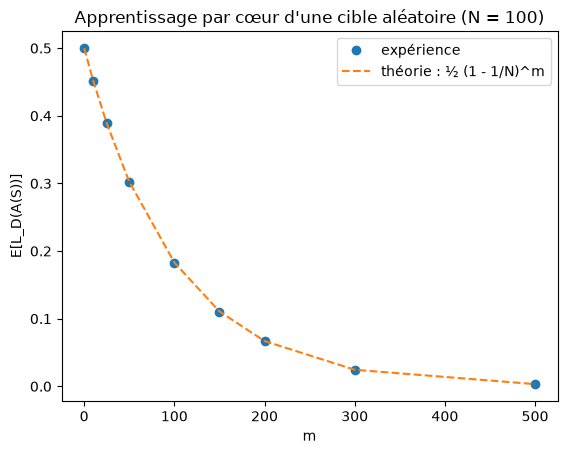

In [9]:
N = 100
M_VALUES_3 = [0, 10, 25, 50, 100, 150, 200, 300, 500]

def risque_moyen_aleatoire(N, m, regle="0"):
    risques = []
    for _ in range(N_REPS_2):
        f = tirer_cible_aleatoire(N)
        x_S = tirer_echantillon(N, m)
        pred = apprendre_par_coeur(x_S, f, N, regle)
        risques.append(np.mean(pred != f))
    return np.mean(risques)

risque_alea = [risque_moyen_aleatoire(N, m) for m in M_VALUES_3]
risque_theo = [0.5 * (1 - 1 / N) ** m for m in M_VALUES_3]

print("   m | E[L_D] expérimental | 0.5 (1 - 1/N)^m")
for m, e, t in zip(M_VALUES_3, risque_alea, risque_theo):
    print(f"{m:4d} | {e:19.4f} | {t:15.4f}")

plt.plot(M_VALUES_3, risque_alea, "o", label="expérience")
plt.plot(M_VALUES_3, risque_theo, "--", label="théorie : ½ (1 - 1/N)^m")
plt.xlabel("m"); plt.ylabel("E[L_D(A(S))]"); plt.legend()
plt.title(f"Apprentissage par cœur d'une cible aléatoire (N = {N})")
plt.show()

La simulation suit la formule. L'erreur baisse avec $m$ seulement parce que l'échantillon couvre plus de points. Sur les points non vus, l'algorithme se trompe toujours une fois sur deux. Pour approcher 0, il faut avoir vu presque tout le domaine, donc $m$ nettement plus grand que $N$.

## 8. Changer la prédiction sur les points non vus

On compare trois règles pour les points non vus : toujours 0, toujours 1, ou pile ou face.

   m |   toujours 0 |   toujours 1 | pile ou face
   0 |       0.5009 |       0.4997 |       0.5002
  10 |       0.4522 |       0.4528 |       0.4536
  25 |       0.3903 |       0.3897 |       0.3893
  50 |       0.3014 |       0.3033 |       0.3036
 100 |       0.1835 |       0.1841 |       0.1847
 150 |       0.1101 |       0.1095 |       0.1106
 200 |       0.0670 |       0.0658 |       0.0667
 300 |       0.0245 |       0.0240 |       0.0244
 500 |       0.0032 |       0.0032 |       0.0034


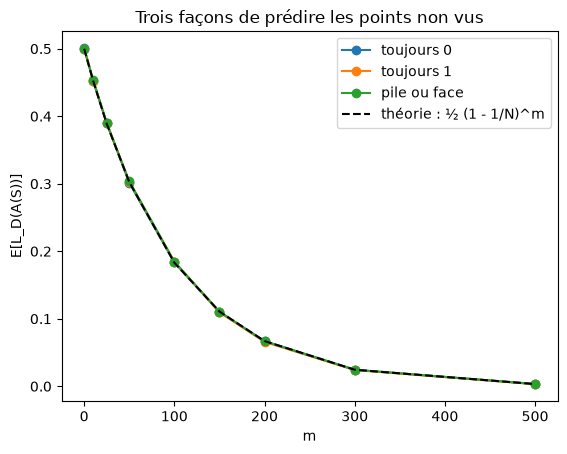

In [10]:
REGLES = {"toujours 0": "0", "toujours 1": "1", "pile ou face": "hasard"}

risques_regles = {}
for nom, regle in REGLES.items():
    risques_regles[nom] = [risque_moyen_aleatoire(N, m, regle) for m in M_VALUES_3]

print("   m | " + " | ".join(f"{nom:>12s}" for nom in REGLES))
for i, m in enumerate(M_VALUES_3):
    print(f"{m:4d} | " + " | ".join(f"{risques_regles[nom][i]:12.4f}" for nom in REGLES))

for nom in REGLES:
    plt.plot(M_VALUES_3, risques_regles[nom], "o-", label=nom)
plt.plot(M_VALUES_3, risque_theo, "k--", label="théorie : ½ (1 - 1/N)^m")
plt.xlabel("m"); plt.ylabel("E[L_D(A(S))]"); plt.legend()
plt.title("Trois façons de prédire les points non vus")
plt.show()

Aux fluctuations Monte-Carlo près, les trois règles donnent la même erreur moyenne, et aucune ne fait mieux que les autres sur l'ensemble des $m$.

On retrouve le No-Free-Lunch. Quand la cible est tirée complètement au hasard, le label d'un point non vu est indépendant de tout ce qui a été observé, donc chaque règle a une chance sur deux de se tromper sur ce point. Une règle peut gagner sur une cible particulière (« toujours 0 » ne fait aucune erreur si la cible vaut 0 partout), mais elle perd autant sur d'autres cibles. En moyenne sur toutes les cibles, les règles se valent.

# Partie III : Ajouter de la connaissance a priori

On garde le domaine $\{1, \dots, N\}$ mais la cible est maintenant un seuil $f_\theta(x) = \mathbb{1}[x > \theta]$, avec $\theta$ tiré au hasard dans $\{1, \dots, N-1\}$. L'algorithme cherche lui aussi un seuil : sa classe est
$$H = \{h_t(x) = \mathbb{1}[x > t] : t \in \{1, \dots, N-1\}\}.$$

## 9. Apprendre avec le bon biais inductif

ERM essaie les $N-1$ seuils et garde ceux qui font le moins d'erreurs sur l'échantillon. Comme la cible est un seuil, plusieurs seuils font 0 erreur : ce sont ceux compris entre le plus grand point vu avec le label 0 et le plus petit point vu avec le label 1. On prend celui du milieu, comme dans le HW1.

On calcule l'erreur vraie sur tout le domaine, point par point. On pourrait aussi utiliser $L_D(h_t) = |t - \theta| / N$, puisque $h_t$ et $f_\theta$ ne diffèrent que sur les points entre $t$ et $\theta$.

In [11]:
DOMAINE = np.arange(1, N + 1)        # x = 1, ..., N
SEUILS = np.arange(1, N)             # t = 1, ..., N-1

def erm_seuil(x_S, y_S):
    # erreur empirique de chaque seuil t
    erreurs = []
    for t in SEUILS:
        erreurs.append(np.mean((x_S > t).astype(int) != y_S) if len(x_S) > 0 else 0)
    erreurs = np.array(erreurs)
    meilleurs = SEUILS[erreurs == erreurs.min()]   # tous les seuils ex aequo
    return meilleurs[len(meilleurs) // 2]          # celui du milieu

def risque_moyen_seuil(N, m):
    risques = []
    for _ in range(N_REPS_2):
        theta = rng.integers(1, N)                 # θ dans {1, ..., N-1}
        f = (DOMAINE > theta).astype(int)          # cible sur tout le domaine
        x_S = rng.integers(1, N + 1, m)            # échantillon uniforme
        y_S = (x_S > theta).astype(int)
        t = erm_seuil(x_S, y_S)
        pred = (DOMAINE > t).astype(int)
        risques.append(np.mean(pred != f))
    return np.mean(risques)

risque_seuil = [risque_moyen_seuil(N, m) for m in M_VALUES_3]

print("   m | cible aléatoire (par cœur) | cible seuil (ERM sur les seuils)")
for m, ra, rs in zip(M_VALUES_3, risque_alea, risque_seuil):
    print(f"{m:4d} | {ra:26.4f} | {rs:32.4f}")

   m | cible aléatoire (par cœur) | cible seuil (ERM sur les seuils)
   0 |                     0.4997 |                           0.2534
  10 |                     0.4515 |                           0.0396
  25 |                     0.3896 |                           0.0186
  50 |                     0.3027 |                           0.0095
 100 |                     0.1826 |                           0.0041
 150 |                     0.1099 |                           0.0022
 200 |                     0.0670 |                           0.0015
 300 |                     0.0238 |                           0.0005
 500 |                     0.0032 |                           0.0001


Avec 0 exemple, le seuil du milieu a déjà une erreur d'environ 0,25, contre 0,5 pour la cible aléatoire, simplement parce qu'on sait que la cible est un seuil. L'écart grandit très vite avec quelques exemples : à $m = 50$, ERM sur les seuils se trompe sur environ 1 % du domaine, et l'apprentissage par cœur d'une cible aléatoire sur environ 30 %.

## 10. Cibles aléatoires contre cibles structurées

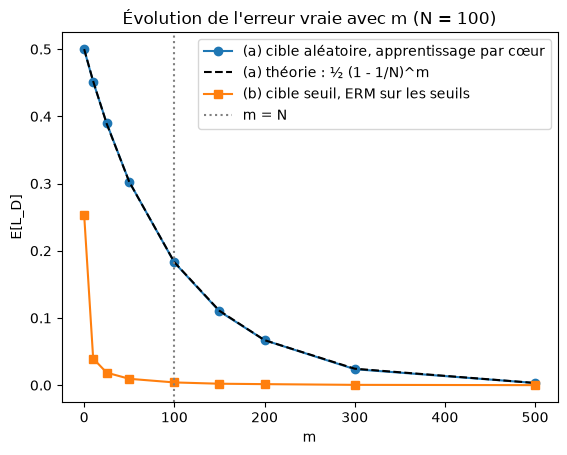

In [12]:
plt.plot(M_VALUES_3, risque_alea, "o-", label="(a) cible aléatoire, apprentissage par cœur")
plt.plot(M_VALUES_3, risque_theo, "k--", label="(a) théorie : ½ (1 - 1/N)^m")
plt.plot(M_VALUES_3, risque_seuil, "s-", label="(b) cible seuil, ERM sur les seuils")
plt.axvline(N, color="gray", ls=":", label="m = N")
plt.xlabel("m"); plt.ylabel("E[L_D]"); plt.legend()
plt.title(f"Évolution de l'erreur vraie avec m (N = {N})")
plt.show()

Avec une cible aléatoire, connaître $f(x)$ ne renseigne pas sur $f(x+1)$. L'algorithme doit voir les points un par un, et l'erreur baisse au rythme de la fraction non vue.

Avec une cible seuil, un exemple renseigne sur beaucoup de points non vus. Si on observe $f(30) = 0$, on sait que $f(x) = 0$ pour tout $x \le 30$. Si on observe $f(60) = 1$, on sait que $f(x) = 1$ pour tout $x \ge 60$. Il ne reste un doute que sur l'intervalle entre le plus grand 0 vu et le plus petit 1 vu, et cet intervalle rétrécit vite. À $m = 50$, environ 60 % des points ne sont pas dans l'échantillon et l'erreur est pourtant d'environ 1 %.

Ce raisonnement suppose que la cible appartient à la famille des seuils. C'est cette hypothèse qui permet de déduire les labels non vus à partir des labels vus. Si la cible n'était pas un seuil, par exemple une cible aléatoire, ces déductions seraient fausses et ERM sur les seuils ferait de grosses erreurs.

## 11. Conclusion

$L_S(h)$ est une moyenne de $m$ erreurs indépendantes. Sa moyenne est $L_D(h)$ et son écart-type $\sqrt{p(1-p)/m}$ diminue quand $m$ augmente, donc $L_S(h)$ se concentre autour de $L_D(h)$ (partie 1). Hoeffding donne une borne chiffrée : $\Pr[|L_S - L_D| > \varepsilon] \le 2e^{-2m\varepsilon^2}$ (partie 2).

Pour ERM, contrôler une hypothèse fixée ne suffit pas. ERM choisit l'hypothèse qui a la plus petite erreur empirique, et il peut tomber sur une hypothèse dont l'erreur empirique est trompeuse. Il faut donc que $\Delta_S = \max_h |L_S(h) - L_D(h)|$ soit petit, c'est-à-dire que toutes les hypothèses soient bien estimées en même temps (partie 3). Ce contrôle simultané devient plus difficile quand $|H|$ grandit, puisque plus d'hypothèses peuvent s'écarter de leur vraie erreur. Le nombre d'exemples nécessaire n'augmente pourtant que comme $\log|H|$ (parties 4 et 5).

Les bornes pour les classes finies combinent Hoeffding et la borne de l'union, qui prennent chacune le pire cas. Elles sont toujours vraies, mais elles demandent 1,5 à 1,9 fois plus d'exemples que ce qu'on a mesuré (partie 5).

Avec une cible complètement aléatoire, les labels des points non vus sont indépendants de l'échantillon, et toute prédiction sur ces points se trompe une fois sur deux (parties 6 et 7). Les trois règles testées donnent la même erreur moyenne $\frac{1}{2}(1-1/N)^m$ (partie 8). C'est le No-Free-Lunch : à partir de l'échantillon seul, l'algorithme ne peut pas deviner des labels arbitraires, il connaît seulement ce qu'il a vu.

En imposant que la cible et les hypothèses soient des seuils, on ajoute de la connaissance a priori : on cherche parmi $N-1$ seuils au lieu des $2^N$ fonctions possibles (partie 9). Chaque exemple fixe alors le label de tout un intervalle de points, et l'erreur devient presque nulle alors que la plupart des points n'ont jamais été vus (partie 10). Ce biais inductif permet à l'algorithme de généraliser au-delà des exemples observés.